# Quickstart: predict held-out and unseen genes in a fetal-heart MERFISH sample

This tutorial runs RESONATE end to end on the small sample data (`sample_data/`, about 12 MB): a window of a 13 PCW human
fetal-heart MERFISH section (236-gene panel) and a matched scRNA-seq reference (Farah et al., *Nature* 2024, CC0).

1. load the data and embeddings;
2. hold out 48 measured genes, `prepare`, `fit`, `predict`, and score the held-out genes against their measured values;
3. predict genes that are not in the panel at all, with no refit.

It runs on a laptop CPU in about ten minutes (`TUTORIAL_SETTINGS` below caps training at 12 epochs per stage; the model and
all other settings are the paper defaults). Scores from this short run are therefore lower than those of a fully trained model.

In [1]:
import time, warnings
import numpy as np, anndata as ad, matplotlib.pyplot as plt
import resonate
warnings.filterwarnings("ignore")
print("resonate", resonate.__version__)
DATA = "../sample_data/"

resonate 0.1.0.dev0


## 1. The data

In [2]:
spatial   = ad.read_h5ad(DATA + "fetal_heart_spatial.h5ad")
reference = ad.read_h5ad(DATA + "fetal_heart_reference.h5ad")
emb       = resonate.load_gene_embeddings(DATA + "scgpt_spatial_embeddings_subset.npz")
held_out  = open(DATA + "held_out_genes.txt").read().split()
print(spatial)
print(reference)
print(f"embeddings: {len(emb)} genes x {emb.dim}; held-out genes: {len(held_out)}")

AnnData object with n_obs × n_vars = 12000 × 236
    obs: 'section', 'stage', 'author_fine', 'split'
    obsm: 'spatial'
AnnData object with n_obs × n_vars = 8011 × 2244
    obs: 'donor', 'author_label'
embeddings: 2244 genes x 512; held-out genes: 48


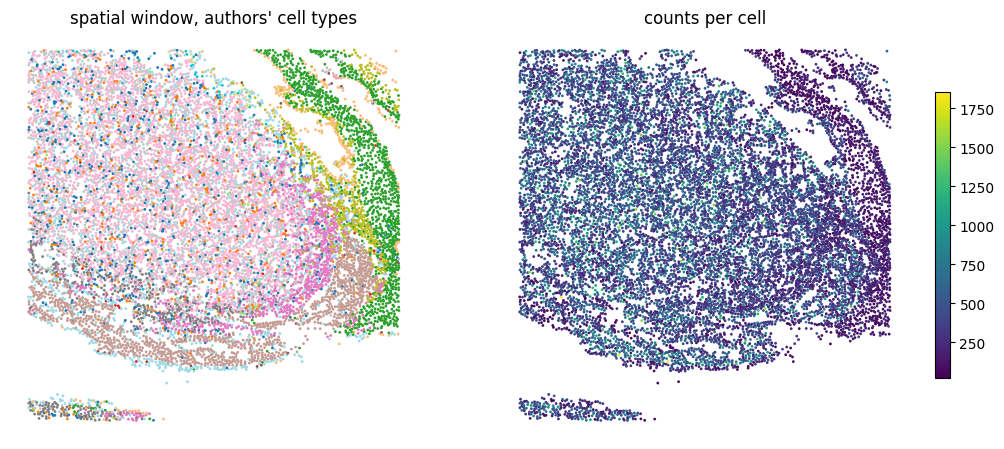

In [3]:
xy = spatial.obsm["spatial"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
ax[0].scatter(xy[:, 0], xy[:, 1], c=spatial.obs["author_fine"].astype("category").cat.codes, s=1, cmap="tab20")
ax[0].set_title("spatial window, authors' cell types"); ax[0].set_aspect("equal"); ax[0].axis("off")
tot = np.asarray(spatial.X.sum(1)).ravel()
im = ax[1].scatter(xy[:, 0], xy[:, 1], c=tot, s=1, cmap="viridis"); ax[1].set_title("counts per cell"); ax[1].set_aspect("equal"); ax[1].axis("off")
plt.colorbar(im, ax=ax[1], shrink=0.7); plt.tight_layout(); plt.show()

The inputs are raw counts. The spatial object carries coordinates (`obsm["spatial"]`), a section label and a train / val /
test split; the reference carries a donor label that is used for batch correction. See
[Inputs and outputs](inputs-outputs.md).

## 2. Held-out benchmark

We treat 48 measured genes as if they had never been measured: `target_genes=held_out`. `prepare` removes them from the
input before normalisation, builds smoothed profiles, reference neighbours, reference cell types, cell-type mixtures and
correlations, and keeps their measured values only for scoring.

In [4]:
# Settings for a laptop CPU: at most 12 epochs per stage (about 7 minutes in total). The paper settings
# (up to 500 epochs with early stopping, TF32 / bf16 on a GPU) are the defaults of resonate.Config().
TUTORIAL_SETTINGS = dict(device="cpu", tf32=False, attn_bf16=False, max_epochs=12)
cfg = resonate.Config(**TUTORIAL_SETTINGS)
t0 = time.time()
prep = resonate.prepare(spatial, reference, emb, target_genes=held_out, config=cfg, verbose=False)
print(prep, f"\nprepare: {(time.time() - t0) / 60:.1f} min")
print("reference cell types:", dict(zip(prep.type_names, np.bincount(prep.ref_codes))))

Prepared(12000 spatial cells, 8011 reference cells, 188 measured + 48 target genes, 17 reference types) 
prepare: 2.2 min
reference cell types: {'L00': 1323, 'L01': 1136, 'L02': 916, 'L03': 717, 'L04': 606, 'L05': 540, 'L06': 500, 'L07': 490, 'L08': 322, 'L09': 273, 'L10': 236, 'L11': 231, 'L12': 214, 'L13': 188, 'L14': 123, 'L15': 123, 'small': 73}


`fit` runs the two stages: pre-training on the reference (target genes are reconstruction targets there), then fine-tuning on
the spatial cells. In stage 2, 20 % of the measured genes are set aside as stand-ins for unmeasured genes; they pick the
checkpoint and the attention weight $\lambda$.

In [5]:
t0 = time.time()
model = resonate.fit(prep, cfg, verbose=False)
s1, s2 = model.summary["stage1"], model.summary["stage2"]
print(f"fit: {(time.time() - t0) / 60:.1f} min | stage 1: {s1['n_epochs']} epochs, best {s1['best_epoch']} | "
      f"stage 2: {s2['n_epochs']} epochs, best {s2['best_epoch']} | lambda = {s2['lambda_']:g}")

fit: 5.7 min | stage 1: 12 epochs, best 12 | stage 2: 12 epochs, best 2 | lambda = 0


In [6]:
pred = model.predict()                      # AnnData: cells x the 48 target genes, log-normalised
print(pred)
scores = resonate.score_heldout(prep, pred)  # test cells only
for k in ("top_n", "all_heldout"):
    v = scores[k]
    print(f"{k:12s} {v['n_genes']:3d} genes  Pearson {v['pearson']:.3f}  Spearman {v['spearman']:.3f}  aligned MSE {v['mse']:.3f}")

AnnData object with n_obs × n_vars = 12000 × 48
    obs: 'split'
    var: 'is_fit_target'
    uns: 'resonate'
    obsm: 'spatial'
top_n         47 genes  Pearson 0.386  Spearman 0.312  aligned MSE 0.259
all_heldout   48 genes  Pearson 0.378  Spearman 0.307  aligned MSE 0.254


The headline score is the mean Pearson correlation across test cells over the top-N held-out genes (detected in at least
10 % of cells, up to 100 genes with the highest mean count).

For reference, the same sample run with the uncapped paper settings (early stopping, patience 15; 4 CPU cores) took 19 minutes
for `fit`, trained 64 + 16 epochs and scored top-N Pearson 0.393 (this 12-epoch run: see above). The paper-setting model fitted to the full
dataset (250k spatial cells, 73k reference cells; different test cells) scores 0.44 on the same kind of top-N set. Per-gene numbers and a comparison with
the measured values:

best predicted: [('FBLN2', 0.76), ('IRX1', 0.67), ('MECOM', 0.62), ('BMP2', 0.62), ('PLK1', 0.62)]
worst predicted: [('TFF3', 0.05), ('AGPS', 0.03), ('CTSV', 0.0)]


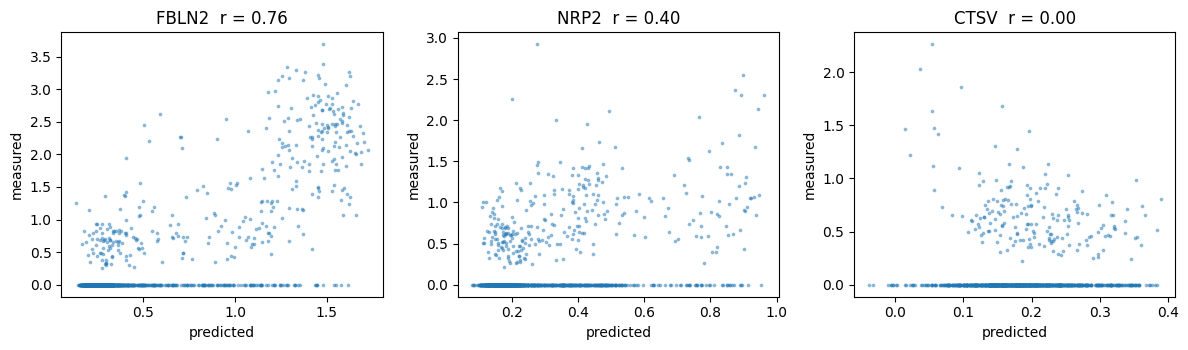

In [7]:
from resonate.metrics import truth_log_expression
truth = truth_log_expression(prep)[prep.te]
P = pred.X[prep.te]
col = {g: j for j, g in enumerate(prep.truth_genes)}
per = scores["top_n"]["per_gene"]["pearson"]; names = scores["top_n_genes"]
order = np.argsort(per)[::-1]
print("best predicted:", [(names[i], round(per[i], 2)) for i in order[:5]])
print("worst predicted:", [(names[i], round(per[i], 2)) for i in order[-3:]])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a, i in zip(ax, [order[0], order[len(order) // 2], order[-1]]):
    g = names[i]; a.scatter(P[:, list(pred.var_names).index(g)], truth[:, col[g]], s=3, alpha=0.4)
    a.set_title(f"{g}  r = {per[i]:.2f}"); a.set_xlabel("predicted"); a.set_ylabel("measured")
plt.tight_layout(); plt.show()

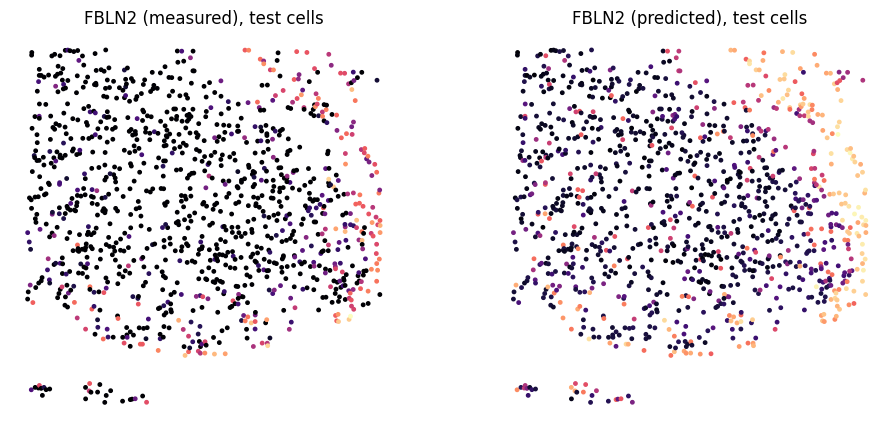

In [8]:
g = names[order[0]]
fig, ax = plt.subplots(1, 2, figsize=(10, 4.4))
xy_te = prep.xy[prep.te]
for a, v, t in zip(ax, (truth[:, col[g]], P[:, list(pred.var_names).index(g)]), ("measured", "predicted")):
    im = a.scatter(xy_te[:, 0], xy_te[:, 1], c=v, s=6, cmap="magma"); a.set_title(f"{g} ({t}), test cells"); a.set_aspect("equal"); a.axis("off")
plt.tight_layout(); plt.show()

## 3. Genes outside the panel

After fitting, any other reference gene that has an embedding can be predicted with the same trained networks (no refit):
pass the reference and the embeddings. Here we predict heart markers that the MERFISH panel does not contain (*NPPA* and *BMP10* are described as atrial-enriched
in the literature). There is no measurement to compare with in this sample, so this is a demonstration of the call, not a
validation; the paper's biological tests use the full data and a random-gene null.

In [9]:
unseen = [g for g in ["NPPA", "HCN4", "BMP10", "MYH7"] if g in reference.var_names and g not in spatial.var_names]
extra = model.predict(unseen, reference=reference, gene_embeddings=emb)
print(extra)
ct = spatial.obs["author_fine"].astype(str).values
import pandas as pd
df = pd.DataFrame(extra.X, columns=unseen); df["cell type"] = ct
top = df.groupby("cell type")[unseen].mean()
print(top.round(2).sort_values(unseen[0], ascending=False).head(8))

AnnData object with n_obs × n_vars = 12000 × 2
    obs: 'split'
    var: 'is_fit_target'
    uns: 'resonate'
    obsm: 'spatial'
                   NPPA  BMP10
cell type                     
aCM-RA             1.91   0.44
vCM-His-Purkinje   1.84   0.54
ncCM-AVC-like      1.80   0.39
vCM-LV-Trabecular  1.80   0.44
vCM-Proliferating  1.79   0.38
vCM-RV-Trabecular  1.78   0.40
vCM-LV-Compact     1.72   0.39
vCM-RV-Compact     1.67   0.34


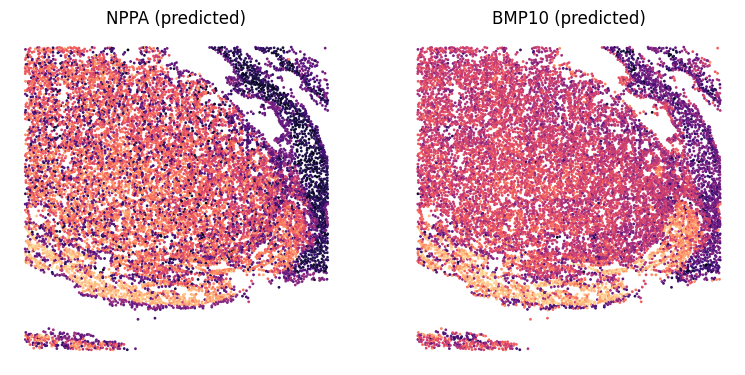

In [10]:
fig, ax = plt.subplots(1, len(unseen), figsize=(4 * len(unseen), 3.8))
for a, g in zip(np.atleast_1d(ax), unseen):
    im = a.scatter(xy[:, 0], xy[:, 1], c=extra[:, g].X.ravel(), s=1, cmap="magma"); a.set_title(f"{g} (predicted)"); a.set_aspect("equal"); a.axis("off")
plt.tight_layout(); plt.show()

## 4. Save and reload

In [11]:
import tempfile, os
d = tempfile.mkdtemp()
prep.save(os.path.join(d, "prepared")); model.save(os.path.join(d, "model"))
model2 = resonate.Resonate.load(os.path.join(d, "model"), resonate.Prepared.load(os.path.join(d, "prepared")), device="cpu")
print("same predictions after reload:", np.allclose(model.predict(as_anndata=False)[0], model2.predict(as_anndata=False)[0], atol=1e-5))

same predictions after reload: True


## Next steps

* Use your own data: [Inputs and outputs](inputs-outputs.md), [choosing a reference and embeddings](choosing-reference-and-embeddings.md).
* Predict unmeasured genes for real: `target_genes=[...]` that are not in `spatial.var_names`; there is nothing to score.
* Command-line use: [Command line](cli.md).